In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [17]:
iris = load_iris()
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
df["target"] = iris.target
print("First 5 Rows:")
display(df.head())
print("\nDataset Shape:", df.shape)

print("\nFeature Names:")
print(iris.feature_names)

print("\nTarget Classes:")
print(iris.target_names)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["target"].value_counts().sort_index())


First 5 Rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset Shape: (150, 5)

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Classes:
['setosa' 'versicolor' 'virginica']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Class Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [18]:
X = df[iris.feature_names]
y = df["target"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=iris.feature_names
)

print("First 5 rows after feature scaling:")
display(X_scaled_df.head())

print("\nMean of each scaled feature:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation of each scaled feature:")
print(X_scaled_df.std().round(2))

print("\nScaled dataset shape:", X_scaled.shape)

First 5 rows after feature scaling:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444



Mean of each scaled feature:
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Standard deviation of each scaled feature:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64

Scaled dataset shape: (150, 4)


K-Means Cluster Counts:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Silhouette Score: 0.4599


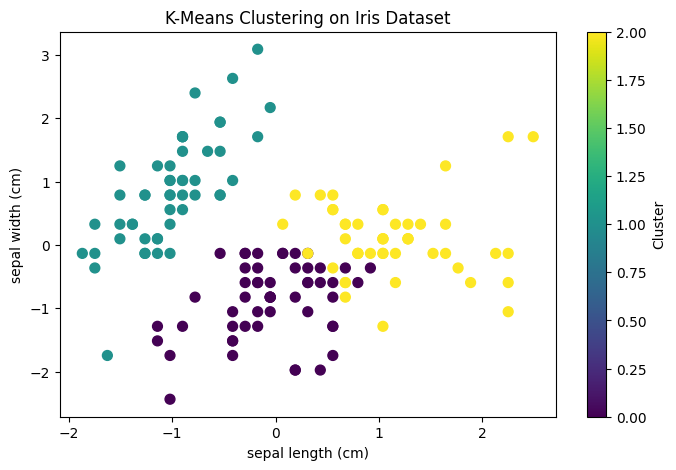

In [19]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster assignments to the dataset
df["KMeans_Cluster"] = clusters

# Display cluster counts
print("K-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

# Calculate Silhouette Score
sil_score = silhouette_score(X_scaled, clusters)
print("\nSilhouette Score:", round(sil_score, 4))

plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("K-Means Clustering on Iris Dataset")
plt.colorbar(label="Cluster")
plt.show()

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

Hierarchical Silhouette Score: 0.4467


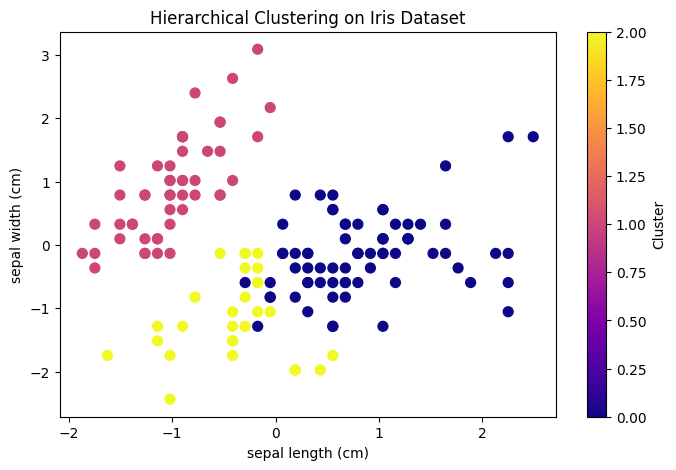

In [20]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_clusters = hierarchical.fit_predict(X_scaled)

df["Hierarchical_Cluster"] = hierarchical_clusters

print("Hierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

hierarchical_score = silhouette_score(X_scaled, hierarchical_clusters)

print("\nHierarchical Silhouette Score:",
      round(hierarchical_score, 4))

plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_clusters,
    cmap="plasma",
    s=50
)
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("Hierarchical Clustering on Iris Dataset")
plt.colorbar(label="Cluster")
plt.show()

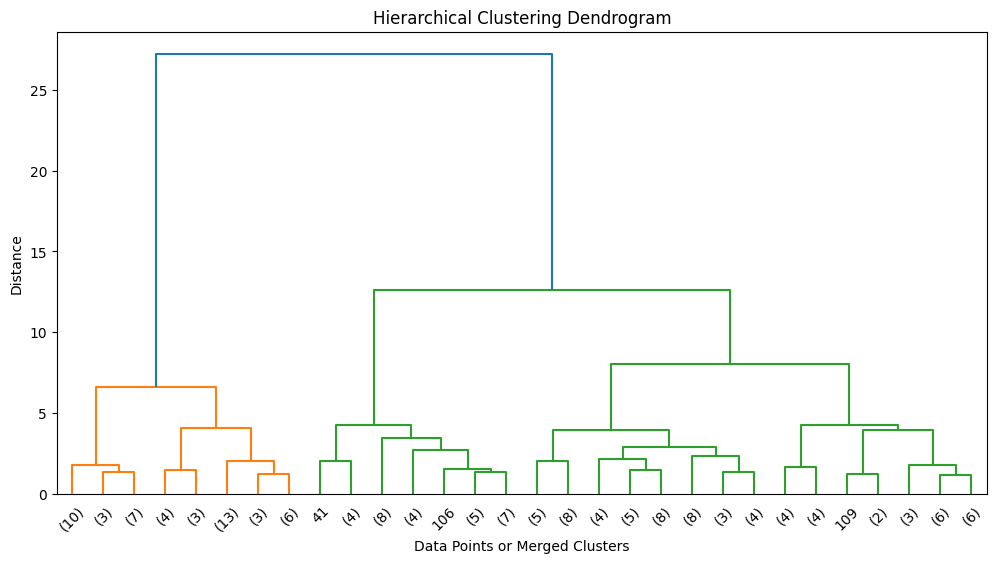

In [21]:
linkage_matrix = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points or Merged Clusters")
plt.ylabel("Distance")
plt.show()

In [22]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

print("First 5 rows after PCA:")
display(pca_df.head())

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Explained:")
print(round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

First 5 rows after PCA:


,Principal Component 1,Principal Component 2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835



Explained Variance Ratio:
[0.7296 0.2285]

Total Variance Explained:
95.81 %


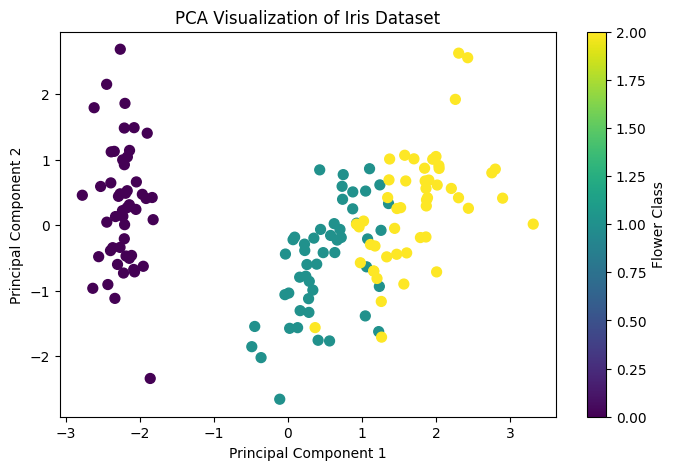

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.colorbar(label="Flower Class")
plt.show()

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Training Completed Successfully!")
print("Predictions:", y_pred[:10])

Training Samples: 120
Testing Samples: 30
Model Training Completed Successfully!
Predictions: [0 2 1 1 0 1 0 0 2 1]


Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

ROC-AUC Score:
0.9967


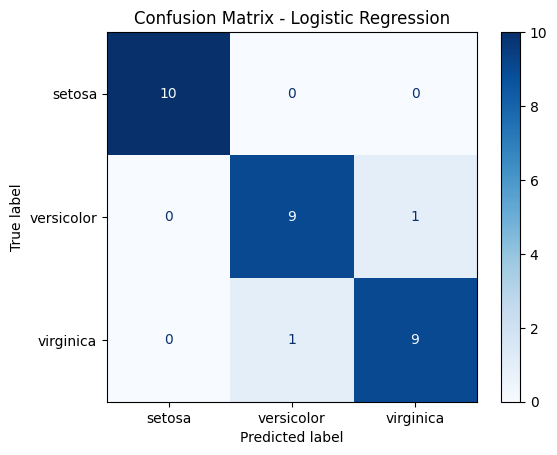

In [25]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nROC-AUC Score:")
roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="macro"
)
print(round(roc_auc, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
).plot(cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [26]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-Validation Scores:")
print(cv_scores.round(4))

print("\nMean Cross-Validation Accuracy:")
print(round(cv_scores.mean(), 4))

print("\nStandard Deviation:")
print(round(cv_scores.std(), 4))

Cross-Validation Scores:
[1.     0.9667 0.9    1.     0.9   ]

Mean Cross-Validation Accuracy:
0.9533

Standard Deviation:
0.0452


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

print("\nTuned Model Test Accuracy:")
print(round(accuracy_score(y_test, best_pred), 4))

print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    best_pred,
    target_names=iris.target_names
))

Best Parameters:
{'classifier__C': 10, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best Cross-Validation Accuracy:
0.9667

Tuned Model Test Accuracy:
1.0

Tuned Model Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



,Algorithm,Silhouette Score,Adjusted Rand Index
0,K-Means,0.4599,0.6201
1,Hierarchical Clustering,0.4467,0.6153


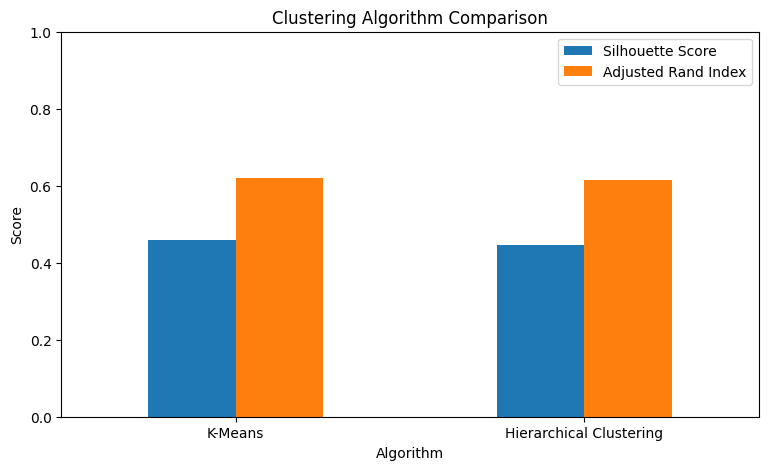

In [28]:
from sklearn.metrics import adjusted_rand_score

kmeans_ari = adjusted_rand_score(y, clusters)
hierarchical_ari = adjusted_rand_score(y, hierarchical_clusters)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical Clustering"],
    "Silhouette Score": [sil_score, hierarchical_score],
    "Adjusted Rand Index": [kmeans_ari, hierarchical_ari]
})

display(comparison.round(4))

comparison.set_index("Algorithm")[
    ["Silhouette Score", "Adjusted Rand Index"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Clustering Algorithm Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="best")
plt.show()

In [29]:
final_results = pd.DataFrame({
    "Evaluation": [
        "Logistic Regression Test Accuracy",
        "Mean Cross-Validation Accuracy",
        "Tuned Model Test Accuracy",
        "ROC-AUC Score",
        "K-Means Silhouette Score",
        "Hierarchical Silhouette Score",
        "K-Means Adjusted Rand Index",
        "Hierarchical Adjusted Rand Index",
        "PCA Variance Explained"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        cv_scores.mean(),
        accuracy_score(y_test, best_pred),
        roc_auc_score(y_test, best_model.predict_proba(X_test),
                      multi_class="ovr", average="macro"),
        sil_score,
        hierarchical_score,
        kmeans_ari,
        hierarchical_ari,
        sum(pca.explained_variance_ratio_)
    ]
})

final_results["Score"] = final_results["Score"].round(4)

display(final_results)

print("\nFinal Summary")
print("Dataset: Iris")
print("Total Samples:", len(df))
print("Features Used:", len(iris.feature_names))
print("Clustering Algorithms: K-Means and Hierarchical Clustering")
print("Dimensionality Reduction: PCA")
print("Classification: Logistic Regression")
print("Cross-Validation: 5-Fold")
print("Hyperparameter Tuning: GridSearchCV")

,Evaluation,Score
0,Logistic Regression Test Accuracy,0.9333
1,Mean Cross-Validation Accuracy,0.9533
2,Tuned Model Test Accuracy,1.0000
3,ROC-AUC Score,1.0000
4,K-Means Silhouette Score,0.4599
5,Hierarchical Silhouette Score,0.4467
6,K-Means Adjusted Rand Index,0.6201
7,Hierarchical Adjusted Rand Index,0.6153
8,PCA Variance Explained,0.9581



Final Summary
Dataset: Iris
Total Samples: 150
Features Used: 4
Clustering Algorithms: K-Means and Hierarchical Clustering
Dimensionality Reduction: PCA
Classification: Logistic Regression
Cross-Validation: 5-Fold
Hyperparameter Tuning: GridSearchCV
